In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

### Load dataset

In [3]:
df = pd.read_csv('/Users/amaree/Downloads/FRSC RTC Report 1960-2024 UD.csv')

df.head()

,Year,Fatal Cases,Serious Cases,Minor Cases,Total Cases,Persons Killed,Persons Injured,Total Casualty
0,1960,826,9065,4239,14130,1083,10216,11299
1,1961,193,9982,5788,15963,1313,10614,11927
2,1962,1263,9159,5895,16317,1578,10341,11919
3,1963,967,6918,11950,19835,1532,7771,9303
4,1964,911,7371,7645,15927,1769,12581,14350


### Clean dataset

In [5]:
numeric_cols = [
    "Fatal Cases",
    "Serious Cases",
    "Minor Cases",
    "Total Cases",
    "Persons Killed",
    "Persons Injured",
    "Total Casualty"
]

for col in numeric_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .astype(float)
    )

df["Year"] = df["Year"].astype(int)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             65 non-null     int64  
 1   Fatal Cases      65 non-null     float64
 2   Serious Cases    65 non-null     float64
 3   Minor Cases      65 non-null     float64
 4   Total Cases      65 non-null     float64
 5   Persons Killed   65 non-null     float64
 6   Persons Injured  65 non-null     float64
 7   Total Casualty   65 non-null     float64
dtypes: float64(7), int64(1)
memory usage: 4.2 KB


In [6]:
df = df[df["Year"] <= 2013].copy()

df.shape

(54, 8)

In [7]:
df.tail()

,Year,Fatal Cases,Serious Cases,Minor Cases,Total Cases,Persons Killed,Persons Injured,Total Casualty
49,2009,2460.0,6024.0,2370.0,10854.0,5693.0,27270.0,32963.0
50,2010,2388.0,6815.0,2182.0,11385.0,6052.0,35691.0,41743.0
51,2011,2840.0,8357.0,1999.0,13196.0,6054.0,41165.0,47219.0
52,2012,2935.0,8277.0,2050.0,13262.0,6092.0,39348.0,45440.0
53,2013,3294.0,8589.0,1700.0,13583.0,6544.0,40057.0,46601.0


In [8]:
df.loc[
    df["Year"].isin([2010, 2011, 2012, 2013]),
    ["Year", "Total Cases"]
]

,Year,Total Cases
50,2010,11385.0
51,2011,13196.0
52,2012,13262.0
53,2013,13583.0


### Dataset validation

The recorded total road traffic accident figures for 2012 and 2013 were 13,262 and 13,583, respectively. These figures match the actual values reported in the validation table of Sanusi et al. (2016), confirming that the dataset is suitable for an approximate reproduction of the study's total-case ARIMA analysis.

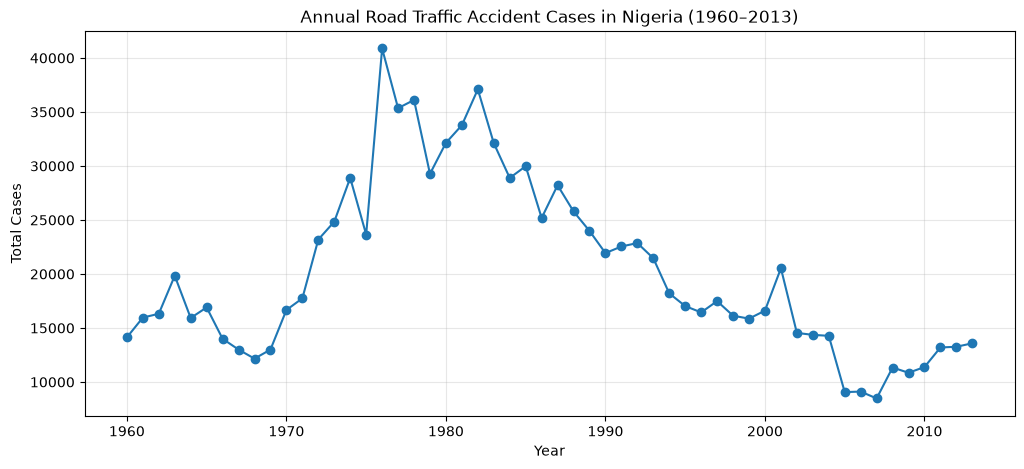

In [10]:
# plot total case series

plt.figure(figsize=(12, 5))

plt.plot(
    df["Year"],
    df["Total Cases"],
    marker="o"
)

plt.title("Annual Road Traffic Accident Cases in Nigeria (1960–2013)")
plt.xlabel("Year")
plt.ylabel("Total Cases")
plt.grid(alpha=0.3)
plt.show()

#### Interpretation

The time-series plot shows considerable fluctuations in the annual number of road traffic accident cases between 1960 and 2013. Accident cases increased significantly during the 1970s and early 1980s, followed by a general decline over the subsequent decades and a gradual increase towards the end of the period.

These changes in the series suggest possible non-stationarity, which is consistent with the findings of Sanusi et al. (2016). A formal stationarity test is therefore conducted before fitting the ARIMA model.

### Model Test

In [13]:
train = df[df["Year"] <= 2011].copy()

validation = df[
    df["Year"].isin([2012, 2013])
].copy()

print("Training observations:", len(train))
print("Validation observations:", len(validation))

print("\nValidation data:")
print(validation[["Year", "Total Cases"]])

Training observations: 52
Validation observations: 2

Validation data:
    Year  Total Cases
52  2012      13262.0
53  2013      13583.0


In [14]:
# test stationarity

def adf_test(series, name):
    result = adfuller(series.dropna())

    print(f"ADF Test: {name}")
    print(f"ADF Statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    print(f"Number of lags: {result[2]}")
    print(f"Number of observations: {result[3]}")

    if result[1] < 0.05:
        print("Result: Stationary")
    else:
        print("Result: Non-stationary")

In [15]:
adf_test(train["Total Cases"], "Total Cases - Level")

ADF Test: Total Cases - Level
ADF Statistic: -1.0384
p-value: 0.7390
Number of lags: 1
Number of observations: 50
Result: Non-stationary


In [16]:
# first differences

train["Total_Cases_Diff1"] = train["Total Cases"].diff()

adf_test(
    train["Total_Cases_Diff1"],
    "Total Cases - First Difference"
)

ADF Test: Total Cases - First Difference
ADF Statistic: -9.9925
p-value: 0.0000
Number of lags: 0
Number of observations: 50
Result: Stationary


#### Stationarity Test

The Augmented Dickey-Fuller (ADF) test was conducted to assess the stationarity of the annual total road traffic crash series. At level, the ADF statistic was -1.0384, with a p-value of 0.7390. As the p-value was greater than the 5% significance level, the null hypothesis of a unit root could not be rejected, suggesting that the original series was non-stationary.

After applying first differencing, the ADF statistic was -9.9925, with a p-value below 0.001. This resulted in the rejection of the null hypothesis, indicating that the differenced series was stationary. The total crash series was therefore considered integrated of order one, I(1), supporting the use of an ARIMA model with d = 1. This finding is consistent with the first-differencing approach used by Sanusi et al. (2016).

### ADF Test

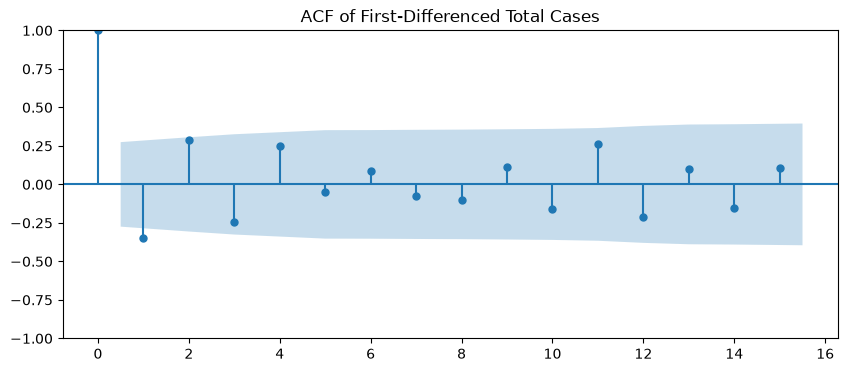

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(
    train["Total_Cases_Diff1"].dropna(),
    lags=15,
    ax=ax
)
plt.title("ACF of First-Differenced Total Cases")
plt.show()

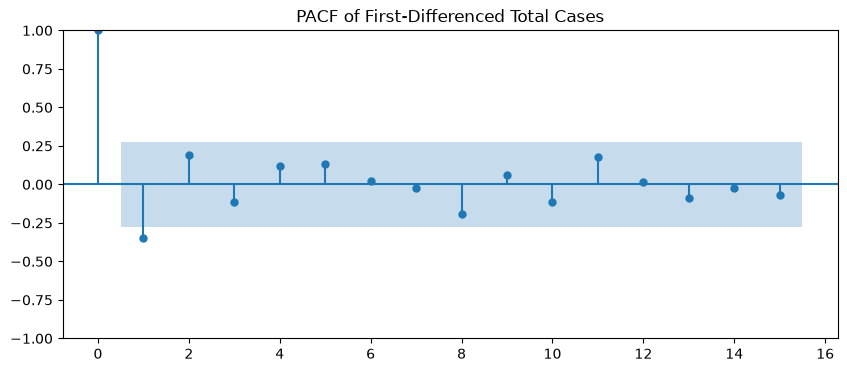

In [20]:
# PACF Test

fig, ax = plt.subplots(figsize=(10, 4))
plot_pacf(
    train["Total_Cases_Diff1"].dropna(),
    lags=15,
    ax=ax,
    method="ywm"
)
plt.title("PACF of First-Differenced Total Cases")
plt.show()

### ACF and PACF Analysis

Following first differencing, the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) plots were examined to identify suitable autoregressive and moving-average components. The ACF plot shows a prominent negative spike at lag 1, while most subsequent autocorrelations fall within the confidence bounds, suggesting a possible MA(1) component. Similarly, the PACF plot shows its strongest negative spike at lag 1, with relatively small partial autocorrelations at subsequent lags, suggesting that an AR(1) component may also be appropriate.

Combined with the ADF test results, which indicated that first differencing was necessary to achieve stationarity, these observations suggest that ARIMA(1,1,1) is a suitable candidate model. This is also consistent with the ARIMA(1,1,1) specification selected by Sanusi et al. (2016) for forecasting total road traffic accident cases.

In [22]:
model_111 = ARIMA(
    train["Total Cases"],
    order=(1, 1, 1)
)

fit_111 = model_111.fit()

print(fit_111.summary())

                               SARIMAX Results                                
Dep. Variable:            Total Cases   No. Observations:                   52
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -489.239
Date:                Thu, 17 Sep 2026   AIC                            984.479
Time:                        11:46:18   BIC                            990.274
Sample:                             0   HQIC                           986.693
                                 - 52                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6780      0.304     -2.234      0.026      -1.273      -0.083
ma.L1          0.4684      0.377      1.241      0.215      -0.271       1.208
sigma2      1.235e+07   1.64e+06      7.534      0.0

In [23]:
forecast_111 = fit_111.forecast(steps=2)

comparison = pd.DataFrame({
    "Year": validation["Year"].values,
    "Actual": validation["Total Cases"].values,
    "Our_ARIMA_111": forecast_111.values,
    "Sanusi_Forecast": [12962.39, 13146.40]
})

comparison

,Year,Actual,Our_ARIMA_111,Sanusi_Forecast
0,2012,13262.0,12969.130339,12962.39
1,2013,13583.0,13122.952340,13146.40


### ARIMA(1,1,1) Replication

An ARIMA(1,1,1) model was fitted using annual total road traffic crash data from 1960 to 2011, following the model specification and validation approach adopted by Sanusi et al. (2016). The fitted model was then used to generate forecasts for the held-out years, 2012 and 2013.

The model produced forecasts of 12,969.13 cases for 2012 and 13,122.95 cases for 2013, compared with the actual recorded values of 13,262 and 13,583, respectively. For the same period, Sanusi et al. (2016) reported predicted values of 12,962.39 and 13,146.40 cases.

The reproduced forecasts were therefore closely aligned with the published results, with differences of approximately 6.74 cases in 2012 and 23.45 cases in 2013. These findings indicate that the ARIMA(1,1,1) forecasting approach was successfully approximated using the historical FRSC dataset, although the small differences mean that the results should not be considered an exact replication.

In [25]:
comparison["Our_Error"] = (
    comparison["Actual"] - comparison["Our_ARIMA_111"]
)

comparison["Our_Percentage_Error"] = (
    comparison["Our_Error"] / comparison["Actual"] * 100
)

comparison["Sanusi_Error"] = (
    comparison["Actual"] - comparison["Sanusi_Forecast"]
)

comparison["Sanusi_Percentage_Error"] = (
    comparison["Sanusi_Error"] / comparison["Actual"] * 100
)

comparison.round(2)

,Year,Actual,Our_ARIMA_111,Sanusi_Forecast,Our_Error,Our_Percentage_Error,Sanusi_Error,Sanusi_Percentage_Error
0,2012,13262.0,12969.13,12962.39,292.87,2.21,299.61,2.26
1,2013,13583.0,13122.95,13146.40,460.05,3.39,436.60,3.21


In [26]:
our_mae = mean_absolute_error(
    comparison["Actual"],
    comparison["Our_ARIMA_111"]
)

our_rmse = np.sqrt(
    mean_squared_error(
        comparison["Actual"],
        comparison["Our_ARIMA_111"]
    )
)

sanusi_mae = mean_absolute_error(
    comparison["Actual"],
    comparison["Sanusi_Forecast"]
)

sanusi_rmse = np.sqrt(
    mean_squared_error(
        comparison["Actual"],
        comparison["Sanusi_Forecast"]
    )
)

replication_metrics = pd.DataFrame({
    "Model": [
        "Reproduced ARIMA(1,1,1)",
        "Sanusi et al. ARIMA(1,1,1)"
    ],
    "MAE": [our_mae, sanusi_mae],
    "RMSE": [our_rmse, sanusi_rmse]
})

replication_metrics.round(2)

,Model,MAE,RMSE
0,"Reproduced ARIMA(1,1,1)",376.46,385.63
1,"Sanusi et al. ARIMA(1,1,1)",368.11,374.42


### Replication Performance

The reproduced ARIMA(1,1,1) model achieved an MAE of 376.46 and an RMSE of 385.63 for the 2012–2013 validation period. These results were closely aligned with the forecasts reported by Sanusi et al. (2016), which recorded an MAE of 368.11 and an RMSE of 374.42 for the same period.

For the individual years, the reproduced model recorded percentage forecast errors of 2.21% in 2012 and 3.39% in 2013, compared with 2.26% and 3.21%, respectively, for the published forecasts. The small differences between the reproduced and published results suggest that the ARIMA(1,1,1) forecasting approach was successfully approximated. These minor variations may be attributed to differences in software implementation and parameter estimation, although their exact causes have not been established.

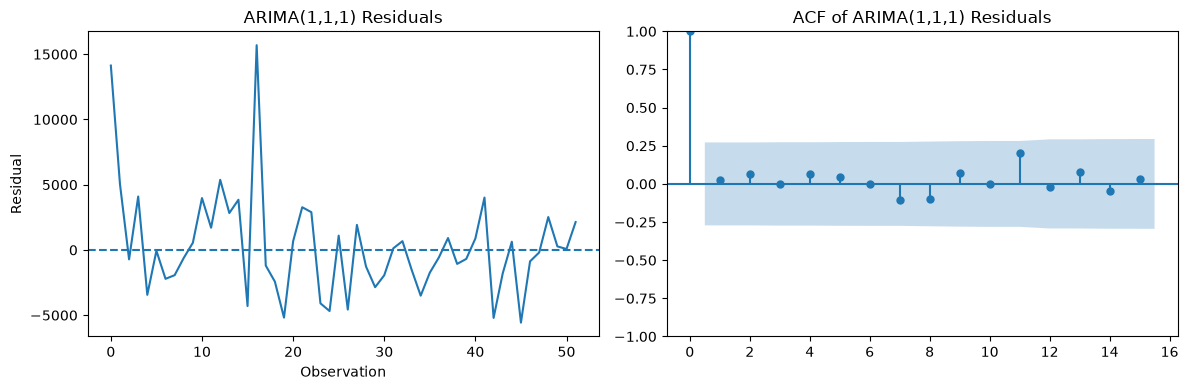

In [28]:
residuals = fit_111.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(residuals)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("ARIMA(1,1,1) Residuals")
axes[0].set_xlabel("Observation")
axes[0].set_ylabel("Residual")

plot_acf(
    residuals.dropna(),
    lags=15,
    ax=axes[1]
)
axes[1].set_title("ACF of ARIMA(1,1,1) Residuals")

plt.tight_layout()
plt.show()

In [29]:
ljung_box = acorr_ljungbox(
    residuals.dropna(),
    lags=[5, 10, 15],
    return_df=True
)

ljung_box

,lb_stat,lb_pvalue
5,0.657033,0.985243
10,2.229969,0.994254
15,5.786284,0.983118


### Residual Diagnostics

Residual diagnostics were conducted to assess whether the fitted ARIMA(1,1,1) model adequately captured the temporal patterns in the training data. Visual examination of the residual ACF plot showed no substantial autocorrelation across the lags examined.

The Ljung–Box test further supported this finding, with p-values of 0.985, 0.994 and 0.983 at lags 5, 10 and 15, respectively. As all p-values exceeded the 5% significance level, the null hypothesis of no residual autocorrelation could not be rejected. This suggests that there was no statistically significant remaining serial dependence in the residuals at the tested lags.

However, additional model diagnostics indicated deviations from residual normality and constant variance. Therefore, although the ARIMA(1,1,1) model appears to have adequately captured the main temporal patterns in the series, some residual assumptions were not fully satisfied.

In [31]:
# ADF stationarity tests for the remaining three crash-severity series

severity_variables = [
    "Minor Cases",
    "Serious Cases",
    "Fatal Cases"
]

for variable in severity_variables:
    print("=" * 60)
    
    # Test original series
    adf_test(
        train[variable],
        f"{variable} - Level"
    )
    
    print()
    
    # Create and test first difference
    first_diff = train[variable].diff()
    
    adf_test(
        first_diff,
        f"{variable} - First Difference"
    )
    
    print()

ADF Test: Minor Cases - Level
ADF Statistic: -1.3053
p-value: 0.6267
Number of lags: 5
Number of observations: 46
Result: Non-stationary

ADF Test: Minor Cases - First Difference
ADF Statistic: -9.9206
p-value: 0.0000
Number of lags: 0
Number of observations: 50
Result: Stationary

ADF Test: Serious Cases - Level
ADF Statistic: -1.3754
p-value: 0.5940
Number of lags: 1
Number of observations: 50
Result: Non-stationary

ADF Test: Serious Cases - First Difference
ADF Statistic: -11.0364
p-value: 0.0000
Number of lags: 0
Number of observations: 50
Result: Stationary

ADF Test: Fatal Cases - Level
ADF Statistic: -2.5685
p-value: 0.0997
Number of lags: 0
Number of observations: 51
Result: Non-stationary

ADF Test: Fatal Cases - First Difference
ADF Statistic: -9.0240
p-value: 0.0000
Number of lags: 0
Number of observations: 50
Result: Stationary



#### Stationarity Tests for Crash Severity Series

The Augmented Dickey-Fuller (ADF) test was conducted separately for Minor, Serious and Fatal crash cases using the 1960–2011 training period.

At level, Minor Cases (p = 0.6267), Serious Cases (p = 0.5940) and Fatal Cases (p = 0.0997) all recorded p-values greater than the 5% significance level. As a result, the null hypothesis of a unit root could not be rejected, suggesting that all three series were non-stationary at level.

After applying first differencing, all three series recorded p-values below 0.001, indicating that they were stationary following differencing. The series were therefore considered integrated of order one, I(1), supporting the use of d = 1 in their respective ARIMA models. This is consistent with the first-order differencing approach adopted by Sanusi et al. (2016).

### ACF and PACF Plots

In [56]:
# Create first-differenced series

train["Minor_Cases_Diff1"] = train["Minor Cases"].diff()
train["Serious_Cases_Diff1"] = train["Serious Cases"].diff()
train["Fatal_Cases_Diff1"] = train["Fatal Cases"].diff()

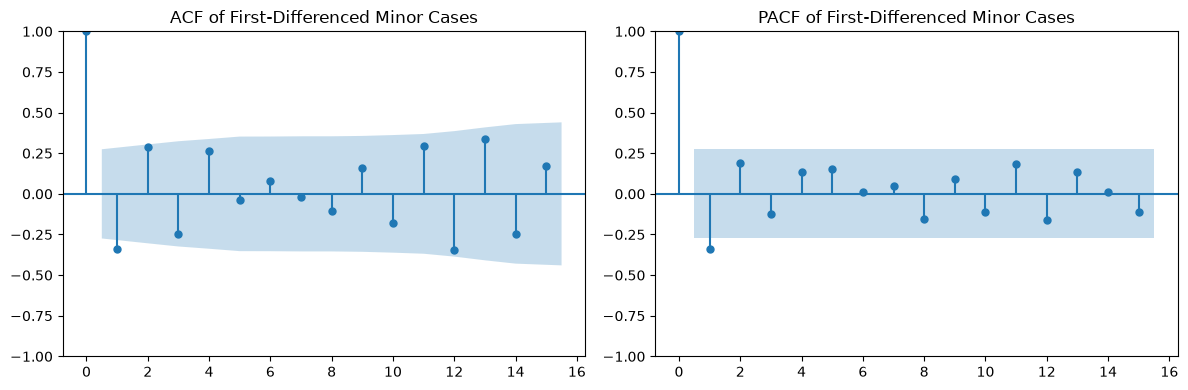

In [58]:
# plot Minor Cases

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(
    train["Minor_Cases_Diff1"].dropna(),
    lags=15,
    ax=axes[0]
)
axes[0].set_title("ACF of First-Differenced Minor Cases")

plot_pacf(
    train["Minor_Cases_Diff1"].dropna(),
    lags=15,
    ax=axes[1],
    method="ywm"
)
axes[1].set_title("PACF of First-Differenced Minor Cases")

plt.tight_layout()
plt.show()

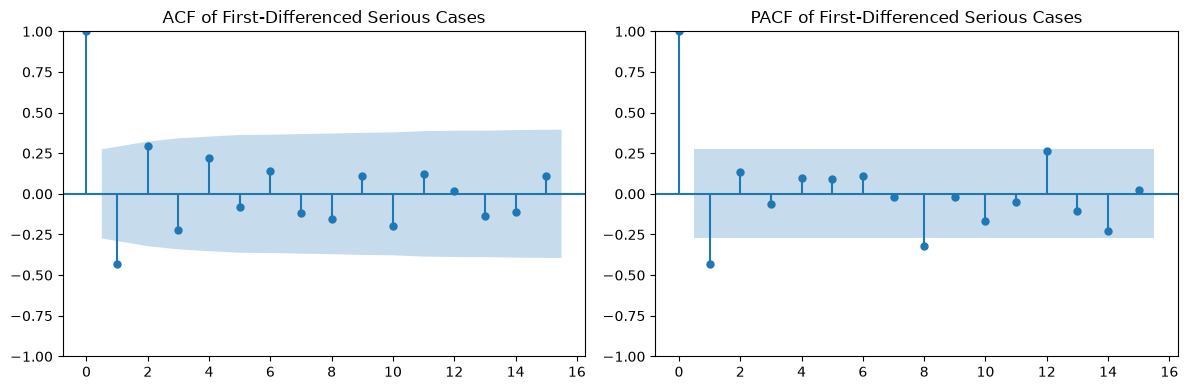

In [60]:
# plot Serious Cases

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(
    train["Serious_Cases_Diff1"].dropna(),
    lags=15,
    ax=axes[0]
)
axes[0].set_title("ACF of First-Differenced Serious Cases")

plot_pacf(
    train["Serious_Cases_Diff1"].dropna(),
    lags=15,
    ax=axes[1],
    method="ywm"
)
axes[1].set_title("PACF of First-Differenced Serious Cases")

plt.tight_layout()
plt.show()

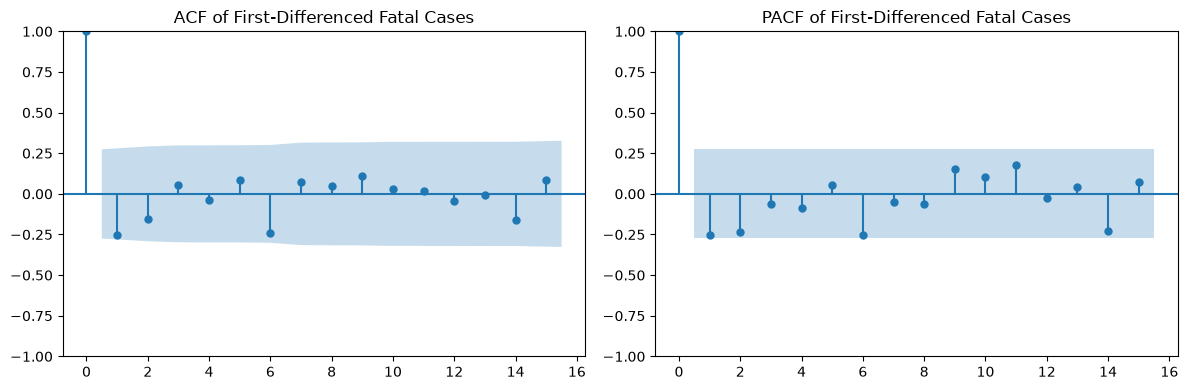

In [62]:
# plot Fatal Cases

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(
    train["Fatal_Cases_Diff1"].dropna(),
    lags=15,
    ax=axes[0]
)
axes[0].set_title("ACF of First-Differenced Fatal Cases")

plot_pacf(
    train["Fatal_Cases_Diff1"].dropna(),
    lags=15,
    ax=axes[1],
    method="ywm"
)
axes[1].set_title("PACF of First-Differenced Fatal Cases")

plt.tight_layout()
plt.show()

#### ACF and PACF Identification of Severity Models

Following first differencing, the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) plots were examined separately for each crash severity series to identify suitable autoregressive and moving-average components.

For Minor Cases, the ACF and PACF plots showed their strongest negative spikes at lag 1, while most subsequent values remained within the confidence bounds. This suggests that low-order AR and MA components may be appropriate, which is broadly consistent with the ARIMA(1,1,1) model used by Sanusi et al. (2016).

For Serious Cases, the PACF plot showed a prominent negative spike at lag 1, suggesting that a first-order autoregressive component may be suitable. Combined with the first-order differencing established by the ADF test, this is consistent with the ARIMA(1,1,0) specification reported by Sanusi et al. (2016). However, the ACF and PACF plots alone are not sufficient to confirm this model, making further evaluation through model estimation and residual diagnostics necessary.

For Fatal Cases, the ACF plot showed a negative autocorrelation at lag 1, while the PACF did not show a clear autoregressive pattern. This suggests that a low-order moving-average component without an autoregressive term may be appropriate, which is consistent with the ARIMA(0,1,1) model selected by Sanusi et al. (2016).

Overall, the ACF and PACF results provide reasonable support for the ARIMA specifications adopted in the original study. However, these plots serve as guides for identifying potential models rather than providing definitive evidence of the most suitable specification.

### Model Estimation

In [65]:
# Minor Cases: Sanusi ARIMA(1,1,1)
# combine both
minor_model = ARIMA(
    train["Minor Cases"],
    order=(1, 1, 1)
)

minor_fit = minor_model.fit()

print(minor_fit.summary())

                               SARIMAX Results                                
Dep. Variable:            Minor Cases   No. Observations:                   52
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -458.737
Date:                Thu, 17 Sep 2026   AIC                            923.474
Time:                        12:03:01   BIC                            929.269
Sample:                             0   HQIC                           925.688
                                 - 52                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.7043      0.299     -2.354      0.019      -1.291      -0.118
ma.L1          0.4553      0.379      1.201      0.230      -0.287       1.198
sigma2      3.768e+06   5.38e+05      7.005      0.0

In [67]:
# Serious Cases: Sanusi ARIMA(1,1,0)
# first difference the serious cases once, then estimate an AR model using one lag and no MA component
serious_model = ARIMA(
    train["Serious Cases"],
    order=(1, 1, 0)
)

serious_fit = serious_model.fit()

print(serious_fit.summary())

                               SARIMAX Results                                
Dep. Variable:          Serious Cases   No. Observations:                   52
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -450.883
Date:                Thu, 17 Sep 2026   AIC                            905.767
Time:                        12:03:10   BIC                            909.630
Sample:                             0   HQIC                           907.243
                                 - 52                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3118      0.100     -3.121      0.002      -0.508      -0.116
sigma2      2.616e+06   2.84e+05      9.198      0.000    2.06e+06    3.17e+06
Ljung-Box (L1) (Q):                   0.47   Jarque-

In [69]:
# Fatal Cases: Sanusi ARIMA(0,1,1)
# first difference the fatal cases once, don't include an AR term and estimate one MA term
fatal_model = ARIMA(
    train["Fatal Cases"],
    order=(0, 1, 1)
)

fatal_fit = fatal_model.fit()

print(fatal_fit.summary())

                               SARIMAX Results                                
Dep. Variable:            Fatal Cases   No. Observations:                   52
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -427.909
Date:                Thu, 17 Sep 2026   AIC                            859.818
Time:                        12:03:19   BIC                            863.682
Sample:                             0   HQIC                           861.294
                                 - 52                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3977      0.125     -3.179      0.001      -0.643      -0.152
sigma2      1.135e+06   2.62e+05      4.329      0.000    6.21e+05    1.65e+06
Ljung-Box (L1) (Q):                   0.14   Jarque-

#### Estimation of the Sanusi ARIMA Severity Models

The ARIMA models reported by Sanusi et al. (2016) were fitted separately to Minor, Serious and Fatal crash cases using the 1960–2011 training dataset.

For Minor Cases, the ARIMA(1,1,1) model produced a statistically significant AR(1) coefficient (−0.7043, p = 0.019), while the MA(1) coefficient (0.4553, p = 0.230) was not statistically significant at the 5% level. The initial Ljung–Box test showed no significant residual autocorrelation at lag 1 (p = 0.87). However, the residual diagnostics indicated deviations from normality and constant variance.

For Serious Cases, the ARIMA(1,1,0) model produced a statistically significant AR(1) coefficient (−0.3118, p = 0.002). Similarly, the initial Ljung–Box test showed no significant residual autocorrelation at lag 1 (p = 0.49), although the residuals showed deviations from normality and constant variance.

For Fatal Cases, the ARIMA(0,1,1) model produced a statistically significant MA(1) coefficient (−0.3977, p = 0.001). The initial residual diagnostics showed no statistically significant evidence of autocorrelation (Ljung–Box p = 0.71), non-normality (Jarque–Bera p = 0.91) or heteroskedasticity (p = 0.44).

Overall, these results indicate that the ARIMA specifications used by Sanusi et al. (2016) could be estimated using the reconstructed historical training dataset. However, the residual diagnostics showed some limitations, particularly for Minor and Serious Cases. The forecasting performance of the models is evaluated separately using the held-out observations for 2012 and 2013.

### Forecast 2012 and 2013

In [80]:
minor_forecast = minor_fit.forecast(steps=2) # forecast the next two annual observations
serious_forecast = serious_fit.forecast(steps=2)
fatal_forecast = fatal_fit.forecast(steps=2)

severity_comparison = pd.DataFrame({
    "Year": validation["Year"].values,

    "Minor_Actual": validation["Minor Cases"].values,
    "Minor_Our_ARIMA": minor_forecast.values,
    "Minor_Sanusi": [2065.14, 1711.18],

    "Serious_Actual": validation["Serious Cases"].values,
    "Serious_Our_ARIMA": serious_forecast.values,
    "Serious_Sanusi": [7680.32, 7977.27],

    "Fatal_Actual": validation["Fatal Cases"].values,
    "Fatal_Our_ARIMA": fatal_forecast.values,
    "Fatal_Sanusi": [2688.66, 2688.66]
})

severity_comparison.round(2)

,Year,Minor_Actual,Minor_Our_ARIMA,Minor_Sanusi,Serious_Actual,Serious_Our_ARIMA,Serious_Sanusi,Fatal_Actual,Fatal_Our_ARIMA,Fatal_Sanusi
0,2012,2050.0,2055.04,2065.14,8277.0,7876.19,7680.32,2935.0,2690.89,2688.66
1,2013,1700.0,2015.57,1711.18,8589.0,8026.11,7977.27,3294.0,2690.89,2688.66


### Validation Errors

In [83]:
# Calculate percentage errors for each severity outcome

for outcome in ["Minor", "Serious", "Fatal"]:
    
    severity_comparison[f"{outcome}_Our_Error"] = (
        severity_comparison[f"{outcome}_Actual"]
        - severity_comparison[f"{outcome}_Our_ARIMA"]
    )
    
    severity_comparison[f"{outcome}_Our_Pct_Error"] = (
        abs(severity_comparison[f"{outcome}_Our_Error"])
        / severity_comparison[f"{outcome}_Actual"] * 100
    )
    
    severity_comparison[f"{outcome}_Sanusi_Error"] = (
        severity_comparison[f"{outcome}_Actual"]
        - severity_comparison[f"{outcome}_Sanusi"]
    )
    
    severity_comparison[f"{outcome}_Sanusi_Pct_Error"] = (
        abs(severity_comparison[f"{outcome}_Sanusi_Error"])
        / severity_comparison[f"{outcome}_Actual"] * 100
    )

In [86]:
validation_accuracy = pd.DataFrame({
    "Year": severity_comparison["Year"],
    
    "Minor_Our_APE": severity_comparison["Minor_Our_Pct_Error"],
    "Minor_Sanusi_APE": severity_comparison["Minor_Sanusi_Pct_Error"],
    
    "Serious_Our_APE": severity_comparison["Serious_Our_Pct_Error"],
    "Serious_Sanusi_APE": severity_comparison["Serious_Sanusi_Pct_Error"],
    
    "Fatal_Our_APE": severity_comparison["Fatal_Our_Pct_Error"],
    "Fatal_Sanusi_APE": severity_comparison["Fatal_Sanusi_Pct_Error"]
})

validation_accuracy.round(2)

,Year,Minor_Our_APE,Minor_Sanusi_APE,Serious_Our_APE,Serious_Sanusi_APE,Fatal_Our_APE,Fatal_Sanusi_APE
0,2012,0.25,0.74,4.84,7.21,8.32,8.39
1,2013,18.56,0.66,6.55,7.12,18.31,18.38


In [91]:
# calc. MAE and RMSE

results = []

for outcome in ["Minor", "Serious", "Fatal"]:
    
    actual = severity_comparison[f"{outcome}_Actual"]
    
    for label, column in [
        ("Reproduced ARIMA", f"{outcome}_Our_ARIMA"),
        ("Sanusi Published", f"{outcome}_Sanusi")
    ]:
        
        predicted = severity_comparison[column]
        
        mae = mean_absolute_error(actual, predicted)
        rmse = np.sqrt(mean_squared_error(actual, predicted))
        mape = np.mean(abs((actual - predicted) / actual)) * 100
        
        results.append({
            "Outcome": outcome,
            "Forecast": label,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE (%)": mape   # Mean Absolute Percentage Error: On average, what percentage away from the actual value were the forecasts?
        })

severity_metrics = pd.DataFrame(results)

severity_metrics.round(2)

,Outcome,Forecast,MAE,RMSE,MAPE (%)
0,Minor,Reproduced ARIMA,160.30,223.17,9.40
1,Minor,Sanusi Published,13.16,13.31,0.70
2,Serious,Reproduced ARIMA,481.85,488.61,5.70
3,Serious,Sanusi Published,604.20,604.25,7.17
4,Fatal,Reproduced ARIMA,423.61,460.07,13.31
5,Fatal,Sanusi Published,425.84,462.13,13.39


#### Validation Forecast Accuracy: 2012–2013

Forecast accuracy was assessed by comparing the predicted values with the actual recorded values for 2012 and 2013, using MAE, RMSE and MAPE.

For Minor Cases, the reproduced ARIMA(1,1,1) model produced a highly accurate forecast for 2012, with an absolute percentage error of 0.25%. However, the 2013 forecast showed a much larger difference from the actual value, recording an error of 18.56%. As a result, the reproduced model achieved a two-year MAPE of 9.40%, compared with 0.70% for the forecasts reported by Sanusi et al. (2016). This indicates that the published Minor Cases forecasts were not consistently reproduced across both validation years.

For Serious Cases, the reproduced ARIMA(1,1,0) model achieved an MAE of 481.85, RMSE of 488.61 and MAPE of 5.70%. These results were better than those obtained from the published Sanusi forecasts, which recorded an MAE of 604.20, RMSE of 604.25 and MAPE of 7.17%. Although the reproduced predictions differed from the published forecasts, they were closer to the actual FRSC values during the validation period.

For Fatal Cases, the reproduced ARIMA(0,1,1) model generated forecasts that were closely aligned with the published results. The reproduced model recorded a MAPE of 13.31%, compared with 13.39% for the published forecasts. However, both sets of forecasts underestimated the actual recorded values, particularly in 2013.

Overall, the results show varying levels of agreement between the reproduced and published forecasts across the three crash severity categories. They also highlight the difference between reproducing a forecasting approach and achieving accurate predictions. A model may produce results similar to those reported in an earlier study without necessarily providing accurate forecasts of the actual observed values.

In [98]:
# ============================================================
# TEST HOW SANUSI GENERATED THE 2014–2020 FORECASTS
# ============================================================

# Full historical dataset available to Sanusi: 1960–2013
full_1960_2013 = df[
    (df["Year"] >= 1960) &
    (df["Year"] <= 2013)
].copy()

print("Observations:", len(full_1960_2013))
print(
    "Period:",
    full_1960_2013["Year"].min(),
    "-",
    full_1960_2013["Year"].max()
)

Observations: 54
Period: 1960 - 2013


In [100]:
# Refit Sanusi's published ARIMA specifications using 1960–2013

total_fit_full = ARIMA(
    full_1960_2013["Total Cases"],
    order=(1, 1, 1)
).fit()

minor_fit_full = ARIMA(
    full_1960_2013["Minor Cases"],
    order=(1, 1, 1)
).fit()

serious_fit_full = ARIMA(
    full_1960_2013["Serious Cases"],
    order=(1, 1, 0)
).fit()

fatal_fit_full = ARIMA(
    full_1960_2013["Fatal Cases"],
    order=(0, 1, 1)
).fit()

print("All four models successfully refitted using 1960–2013.")

All four models successfully refitted using 1960–2013.


In [102]:
# Approach A:
# Models fitted only through 2011

forecast_total_2011 = fit_111.forecast(steps=9).iloc[2:9].values
forecast_minor_2011 = minor_fit.forecast(steps=9).iloc[2:9].values
forecast_serious_2011 = serious_fit.forecast(steps=9).iloc[2:9].values
forecast_fatal_2011 = fatal_fit.forecast(steps=9).iloc[2:9].values

In [106]:
# Approach B:
# Same ARIMA models refitted through 2013

forecast_total_2013 = total_fit_full.forecast(steps=7).values
forecast_minor_2013 = minor_fit_full.forecast(steps=7).values
forecast_serious_2013 = serious_fit_full.forecast(steps=7).values
forecast_fatal_2013 = fatal_fit_full.forecast(steps=7).values

In [110]:
years = np.arange(2014, 2021)

sanusi_published = pd.DataFrame({
    "Year": years,

    "Total_Sanusi": [
        13001.46, 13115.62, 13025.70, 13096.53,
        13040.74, 13084.68, 13050.07
    ],

    "Minor_Sanusi": [
        1803.93, 1719.13, 1788.32, 1731.87,
        1777.93, 1740.35, 1771.01
    ],

    "Serious_Sanusi": [
        7846.95, 7904.14, 7879.05, 7890.06,
        7885.23, 7887.35, 7886.41
    ],

    "Fatal_Sanusi": [
        2688.66, 2688.66, 2688.66, 2688.66,
        2688.66, 2688.66, 2688.66
    ]
})

sanusi_published

,Year,Total_Sanusi,Minor_Sanusi,Serious_Sanusi,Fatal_Sanusi
0,2014,13001.46,1803.93,7846.95,2688.66
1,2015,13115.62,1719.13,7904.14,2688.66
2,2016,13025.70,1788.32,7879.05,2688.66
3,2017,13096.53,1731.87,7890.06,2688.66
4,2018,13040.74,1777.93,7885.23,2688.66
5,2019,13084.68,1740.35,7887.35,2688.66
6,2020,13050.07,1771.01,7886.41,2688.66


In [147]:
forecast_method_comparison = pd.DataFrame({
    "Year": years,

    # TOTAL
    "Total_Sanusi": sanusi_published["Total_Sanusi"],
    "Total_Fit_2011": forecast_total_2011,
    "Total_Fit_2013": forecast_total_2013,

    # MINOR
    "Minor_Sanusi": sanusi_published["Minor_Sanusi"],
    "Minor_Fit_2011": forecast_minor_2011,
    "Minor_Fit_2013": forecast_minor_2013,

    # SERIOUS
    "Serious_Sanusi": sanusi_published["Serious_Sanusi"],
    "Serious_Fit_2011": forecast_serious_2011,
    "Serious_Fit_2013": forecast_serious_2013,

    # FATAL
    "Fatal_Sanusi": sanusi_published["Fatal_Sanusi"],
    "Fatal_Fit_2011": forecast_fatal_2011,
    "Fatal_Fit_2013": forecast_fatal_2013
})

forecast_method_comparison.round(2)

,Year,Total_Sanusi,Total_Fit_2011,Total_Fit_2013,Minor_Sanusi,Minor_Fit_2011,Minor_Fit_2013,Serious_Sanusi,Serious_Fit_2011,Serious_Fit_2013,Fatal_Sanusi,Fatal_Fit_2011,Fatal_Fit_2013
0,2014,13001.46,13018.66,13472.48,1803.93,2043.37,1804.77,7846.95,7979.37,8492.11,2688.66,2690.89,3115.2
1,2015,13115.62,13089.37,13547.57,1719.13,2023.79,1730.83,7904.14,7993.94,8522.20,2688.66,2690.89,3115.2
2,2016,13025.70,13041.43,13496.56,1788.32,2037.58,1783.01,7879.05,7989.40,8512.85,2688.66,2690.89,3115.2
3,2017,13096.53,13073.93,13531.21,1731.87,2027.86,1746.19,7890.06,7990.81,8515.76,2688.66,2690.89,3115.2
4,2018,13040.74,13051.89,13507.67,1777.93,2034.71,1772.18,7885.23,7990.37,8514.86,2688.66,2690.89,3115.2
5,2019,13084.68,13066.84,13523.66,1740.35,2029.89,1753.84,7887.35,7990.51,8515.14,2688.66,2690.89,3115.2
6,2020,13050.07,13056.71,13512.80,1771.01,2033.28,1766.78,7886.41,7990.47,8515.05,2688.66,2690.89,3115.2


In [114]:
method_results = []

for outcome in ["Total", "Minor", "Serious", "Fatal"]:

    sanusi = forecast_method_comparison[f"{outcome}_Sanusi"]

    for method, column in [
        ("Fit through 2011", f"{outcome}_Fit_2011"),
        ("Refit through 2013", f"{outcome}_Fit_2013")
    ]:

        reproduced = forecast_method_comparison[column]

        mae_vs_sanusi = mean_absolute_error(sanusi, reproduced)
        rmse_vs_sanusi = np.sqrt(
            mean_squared_error(sanusi, reproduced)
        )

        method_results.append({
            "Outcome": outcome,
            "Method": method,
            "MAE_vs_Sanusi": mae_vs_sanusi,
            "RMSE_vs_Sanusi": rmse_vs_sanusi
        })

method_test = pd.DataFrame(method_results)

method_test.round(2)

,Outcome,Method,MAE_vs_Sanusi,RMSE_vs_Sanusi
0,Total,Fit through 2011,16.77,17.85
1,Total,Refit through 2013,453.88,454.18
2,Minor,Fit through 2011,271.13,272.15
3,Minor,Refit through 2013,7.95,9.29
4,Serious,Fit through 2011,106.53,107.21
5,Serious,Refit through 2013,629.82,629.87
6,Fatal,Fit through 2011,2.23,2.23
7,Fatal,Refit through 2013,426.54,426.54


#### Investigation of the Published 2014–2020 Forecasting Procedure

To examine how Sanusi et al. (2016) generated their final forecasts for 2014–2020, two forecasting approaches were compared. The first involved fitting the published ARIMA models using the original 1960–2011 training period and extending the forecasts to 2020. The second involved refitting the same models using observations up to 2013 before generating forecasts for 2014–2020.

For Total Cases, the forecasts generated using the 1960–2011 training period were considerably closer to the published results, with an MAE of 16.77, compared with 453.88 when the model was refitted through 2013. Similar results were observed for Serious Cases (MAE of 106.53 compared with 629.82) and Fatal Cases (MAE of 2.23 compared with 426.54). In particular, the Fatal Cases model fitted through 2011 produced a constant forecast of approximately 2,690.89, which was very close to the published forecast of 2,688.66 for 2014–2020.

However, Minor Cases showed a different pattern. The model refitted using observations through 2013 produced forecasts that were closely aligned with the published results, recording an MAE of 7.95. In comparison, the model fitted using only the 1960–2011 training period recorded a much higher MAE of 271.13.

Overall, these findings suggest that the published forecasts for Total, Serious and Fatal Cases were more closely aligned with models fitted using the 1960–2011 training period. In contrast, the Minor Cases forecasts were more consistent with a model fitted using observations through 2013. However, Sanusi et al. (2016) did not clearly specify whether different final training periods were used for each crash category. Therefore, the exact reason for these differences could not be confirmed. This highlights a limitation in fully reproducing the forecasting procedure reported in the original study.

In [117]:
# Extract the actual observed values for 2014–2020

actual_2014_2020 = df[
    (df["Year"] >= 2014) &
    (df["Year"] <= 2020)
][[
    "Year",
    "Minor Cases",
    "Serious Cases",
    "Fatal Cases",
    "Total Cases"
]].copy()

actual_2014_2020

,Year,Minor Cases,Serious Cases,Fatal Cases,Total Cases


In [119]:
%whos DataFrame

Variable                     Type         Data/Info
---------------------------------------------------
actual_2014_2020             DataFrame    Shape: (0, 5)
comparison                   DataFrame    Shape: (2, 8)
df                           DataFrame    Shape: (54, 8)
forecast_method_comparison   DataFrame    Shape: (7, 13)
full_1960_2013               DataFrame    Shape: (54, 8)
ljung_box                    DataFrame    Shape: (3, 2)
method_test                  DataFrame    Shape: (8, 4)
replication_metrics          DataFrame    Shape: (2, 3)
sanusi_published             DataFrame    Shape: (7, 5)
severity_comparison          DataFrame    Shape: (2, 22)
severity_metrics             DataFrame    Shape: (6, 5)
train                        DataFrame    Shape: (52, 12)
validation                   DataFrame    Shape: (2, 8)
validation_accuracy          DataFrame    Shape: (2, 7)


In [121]:
extended_df = pd.read_csv('/Users/amaree/Downloads/FRSC RTC Report 1960-2024 UD.csv')

extended_df.head()

,Year,Fatal Cases,Serious Cases,Minor Cases,Total Cases,Persons Killed,Persons Injured,Total Casualty
0,1960,826,9065,4239,14130,1083,10216,11299
1,1961,193,9982,5788,15963,1313,10614,11927
2,1962,1263,9159,5895,16317,1578,10341,11919
3,1963,967,6918,11950,19835,1532,7771,9303
4,1964,911,7371,7645,15927,1769,12581,14350


In [125]:
extended_df.tail(12)

,Year,Fatal Cases,Serious Cases,Minor Cases,Total Cases,Persons Killed,Persons Injured,Total Casualty
53,2013,"3,294",8589,1700,13583,6544,40057,46601
54,2014,3117,6356,907,10380,5996,32063,38059
55,2015,2854,6039,841,9734,5440,30478,35918
56,2016,2638,5633,1423,9694,5053,30105,35158
57,2017,2587,5456,1340,9383,5121,31094,36215
58,2018,2739,5849,1153,9741,5181,32220,37401
59,2019,2896,6911,1265,11072,5483,35981,41464
60,2020,2961,7567,1347,11875,5574,33311,38885
61,2021,3218,8324,1485,13027,6205,38073,44278
62,2022,3309,8953,1394,13656,6456,38930,45386


In [127]:
print("Shape:", extended_df.shape)
print("Years:", extended_df["Year"].min(), "-", extended_df["Year"].max())
print(extended_df.columns.tolist())

Shape: (65, 8)
Years: 1960 - 2024
['Year', 'Fatal Cases', 'Serious Cases', 'Minor Cases', 'Total Cases', 'Persons Killed', 'Persons Injured', 'Total Casualty']


In [129]:
actual_2014_2020 = extended_df[
    extended_df["Year"].between(2014, 2020)
][[
    "Year",
    "Minor Cases",
    "Serious Cases",
    "Fatal Cases",
    "Total Cases"
]].copy()

actual_2014_2020

,Year,Minor Cases,Serious Cases,Fatal Cases,Total Cases
54,2014,907,6356,3117,10380
55,2015,841,6039,2854,9734
56,2016,1423,5633,2638,9694
57,2017,1340,5456,2587,9383
58,2018,1153,5849,2739,9741
59,2019,1265,6911,2896,11072
60,2020,1347,7567,2961,11875


In [131]:
#merge actual and forecast

retrospective = actual_2014_2020.merge(
    sanusi_published,
    on="Year"
)

retrospective = retrospective.rename(columns={
    "Minor Cases": "Minor_Actual",
    "Serious Cases": "Serious_Actual",
    "Fatal Cases": "Fatal_Actual",
    "Total Cases": "Total_Actual"
})

retrospective.round(2)

,Year,Minor_Actual,Serious_Actual,Fatal_Actual,Total_Actual,Total_Sanusi,Minor_Sanusi,Serious_Sanusi,Fatal_Sanusi
0,2014,907,6356,3117,10380,13001.46,1803.93,7846.95,2688.66
1,2015,841,6039,2854,9734,13115.62,1719.13,7904.14,2688.66
2,2016,1423,5633,2638,9694,13025.70,1788.32,7879.05,2688.66
3,2017,1340,5456,2587,9383,13096.53,1731.87,7890.06,2688.66
4,2018,1153,5849,2739,9741,13040.74,1777.93,7885.23,2688.66
5,2019,1265,6911,2896,11072,13084.68,1740.35,7887.35,2688.66
6,2020,1347,7567,2961,11875,13050.07,1771.01,7886.41,2688.66


In [149]:
# Convert all actual and forecast columns to numeric values

numeric_columns = [
    "Minor_Actual", "Serious_Actual", "Fatal_Actual", "Total_Actual",
    "Minor_Sanusi", "Serious_Sanusi", "Fatal_Sanusi", "Total_Sanusi"
]

retrospective[numeric_columns] = retrospective[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

# Check the data types
retrospective.dtypes

Year                        int64
Minor_Actual                int64
Serious_Actual              int64
Fatal_Actual                int64
Total_Actual                int64
Total_Sanusi              float64
Minor_Sanusi              float64
Serious_Sanusi            float64
Fatal_Sanusi              float64
Minor_Error               float64
Minor_Absolute_Error      float64
Minor_APE                 float64
Serious_Error             float64
Serious_Absolute_Error    float64
Serious_APE               float64
dtype: object

In [151]:
# annual forecast error

for outcome in ["Minor", "Serious", "Fatal", "Total"]:

    # Forecast error
    retrospective[f"{outcome}_Error"] = (
        retrospective[f"{outcome}_Actual"]
        - retrospective[f"{outcome}_Sanusi"]
    )

    # Absolute error
    retrospective[f"{outcome}_Absolute_Error"] = (
        retrospective[f"{outcome}_Error"].abs()
    )

    # Absolute percentage error
    retrospective[f"{outcome}_APE"] = (
        retrospective[f"{outcome}_Absolute_Error"]
        / retrospective[f"{outcome}_Actual"] * 100
    )

In [153]:
annual_accuracy = retrospective[[
    "Year",
    "Minor_Actual", "Minor_Sanusi", "Minor_APE",
    "Serious_Actual", "Serious_Sanusi", "Serious_APE",
    "Fatal_Actual", "Fatal_Sanusi", "Fatal_APE",
    "Total_Actual", "Total_Sanusi", "Total_APE"
]].copy()

annual_accuracy.round(2)

,Year,Minor_Actual,Minor_Sanusi,Minor_APE,Serious_Actual,Serious_Sanusi,Serious_APE,Fatal_Actual,Fatal_Sanusi,Fatal_APE,Total_Actual,Total_Sanusi,Total_APE
0,2014,907,1803.93,98.89,6356,7846.95,23.46,3117,2688.66,13.74,10380,13001.46,25.25
1,2015,841,1719.13,104.41,6039,7904.14,30.88,2854,2688.66,5.79,9734,13115.62,34.74
2,2016,1423,1788.32,25.67,5633,7879.05,39.87,2638,2688.66,1.92,9694,13025.70,34.37
3,2017,1340,1731.87,29.24,5456,7890.06,44.61,2587,2688.66,3.93,9383,13096.53,39.58
4,2018,1153,1777.93,54.20,5849,7885.23,34.81,2739,2688.66,1.84,9741,13040.74,33.87
5,2019,1265,1740.35,37.58,6911,7887.35,14.13,2896,2688.66,7.16,11072,13084.68,18.18
6,2020,1347,1771.01,31.48,7567,7886.41,4.22,2961,2688.66,9.20,11875,13050.07,9.90


In [155]:
retrospective_results = []

for outcome in ["Minor", "Serious", "Fatal", "Total"]:

    actual = retrospective[f"{outcome}_Actual"]
    predicted = retrospective[f"{outcome}_Sanusi"]

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mape = np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100

    retrospective_results.append({
        "Outcome": outcome,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

retrospective_metrics = pd.DataFrame(retrospective_results)

retrospective_metrics.round(2)

,Outcome,MAE,RMSE,MAPE (%)
0,Minor,579.51,616.31,54.50
1,Serious,1624.03,1767.67,27.43
2,Fatal,182.29,221.49,6.23
3,Total,2790.83,2915.91,27.98


### Interpretation of the Retrospective Forecast Evaluation

The retrospective evaluation showed considerable differences in the forecasting accuracy of the four ARIMA models reported by Sanusi et al. (2016).

For Fatal Cases, the forecasts recorded the lowest overall errors, with an MAE of 182.29, RMSE of 221.49 and MAPE of 6.23%. This suggests that the relatively stable forecasts for fatal crashes remained closer to the actual recorded values between 2014 and 2020.

However, forecasting errors were much higher for the other crash categories. Serious Cases recorded a MAPE of 27.43%, while Total Cases recorded 27.98%. Minor Cases had the highest relative forecasting error, with a MAPE of 54.50%.

The results also showed that forecasting errors did not consistently increase over the forecast period. For Total Cases, the absolute percentage error increased from 25.25% in 2014 to 39.58% in 2017, before declining to 9.90% in 2020. A similar pattern was observed for Serious Cases, where the error increased to 44.61% in 2017 before decreasing to 4.22% in 2020. These changes suggest that variations in the actual recorded crash figures influenced the forecasting errors, rather than accuracy simply declining as the forecast period increased.

Overall, the findings indicate that the accuracy of the published ARIMA models varied considerably across the different crash severity categories. They also highlight the importance of comparing published forecasts with actual recorded values over a longer period, rather than relying only on the original two-year validation results.

#### Next Step

With the availability of 65 years of historical data, the next stage examines whether the ARIMA models used by Sanusi et al. (2016) remain suitable and how accurately they forecast more recent road traffic crash figures in Nigeria.

In [159]:
print("Number of observations:", len(extended_df))
print("Period:", extended_df["Year"].min(), "-", extended_df["Year"].max())

extended_df[[
    "Year",
    "Minor Cases",
    "Serious Cases",
    "Fatal Cases",
    "Total Cases"
]].tail(15)

Number of observations: 65
Period: 1960 - 2024


,Year,Minor Cases,Serious Cases,Fatal Cases,Total Cases
50,2010,2182,6815,2388,11385
51,2011,1999,8357,2840,13196
52,2012,2050,8277,2935,13262
53,2013,1700,8589,"3,294",13583
54,2014,907,6356,3117,10380
55,2015,841,6039,2854,9734
56,2016,1423,5633,2638,9694
57,2017,1340,5456,2587,9383
58,2018,1153,5849,2739,9741
59,2019,1265,6911,2896,11072


In [163]:
case_columns = [
    "Minor Cases",
    "Serious Cases",
    "Fatal Cases",
    "Total Cases"
]

for column in case_columns:
    extended_df[column] = pd.to_numeric(
        extended_df[column].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

# Check the result
extended_df[case_columns].dtypes

Minor Cases      int64
Serious Cases    int64
Fatal Cases      int64
Total Cases      int64
dtype: object

In [165]:
# ADF stationarity tests using the extended 1960–2024 dataset

for column in ["Minor Cases", "Serious Cases", "Fatal Cases", "Total Cases"]:
    
    print("=" * 60)
    
    # Test the original series
    adf_test(
        extended_df[column],
        f"{column} - Level (1960-2024)"
    )
    
    # Create first difference
    diff_series = extended_df[column].diff()
    
    # Test the first-differenced series
    adf_test(
        diff_series,
        f"{column} - First Difference (1960-2024)"
    )

ADF Test: Minor Cases - Level (1960-2024)
ADF Statistic: -1.1603
p-value: 0.6904
Number of lags: 11
Number of observations: 53
Result: Non-stationary
ADF Test: Minor Cases - First Difference (1960-2024)
ADF Statistic: -2.5917
p-value: 0.0947
Number of lags: 11
Number of observations: 52
Result: Non-stationary
ADF Test: Serious Cases - Level (1960-2024)
ADF Statistic: -1.8311
p-value: 0.3651
Number of lags: 2
Number of observations: 62
Result: Non-stationary
ADF Test: Serious Cases - First Difference (1960-2024)
ADF Statistic: -11.7955
p-value: 0.0000
Number of lags: 0
Number of observations: 63
Result: Stationary
ADF Test: Fatal Cases - Level (1960-2024)
ADF Statistic: -2.8553
p-value: 0.0508
Number of lags: 0
Number of observations: 64
Result: Non-stationary
ADF Test: Fatal Cases - First Difference (1960-2024)
ADF Statistic: -10.1013
p-value: 0.0000
Number of lags: 0
Number of observations: 63
Result: Stationary
ADF Test: Total Cases - Level (1960-2024)
ADF Statistic: -1.2034
p-value:

In [171]:
# Second-difference for Minor Cases

minor_diff2 = extended_df["Minor Cases"].diff().diff()

adf_test(
    minor_diff2,
    "Minor Cases - Second Difference (1960-2024)"
)

ADF Test: Minor Cases - Second Difference (1960-2024)
ADF Statistic: -3.6594
p-value: 0.0047
Number of lags: 11
Number of observations: 51
Result: Stationary


### ACF and PACF Plots - Extended 

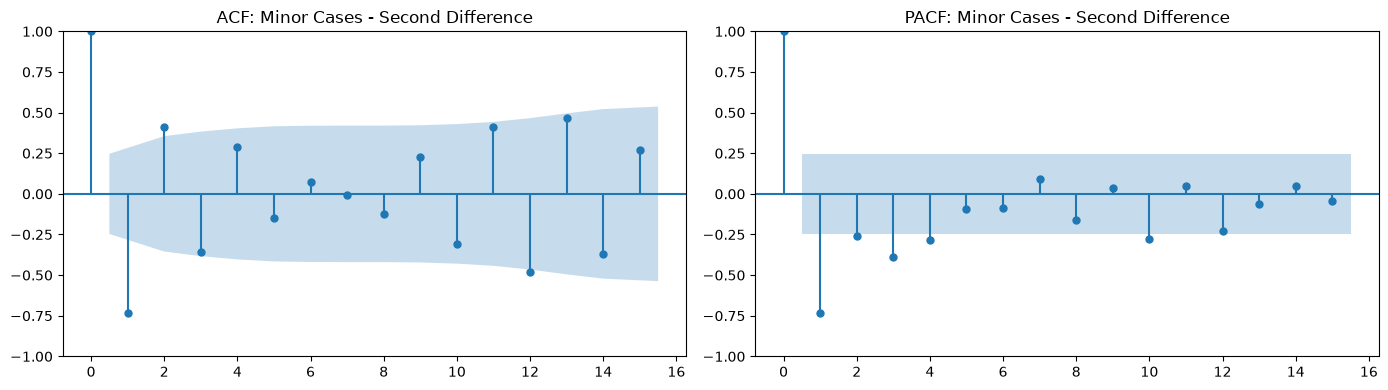

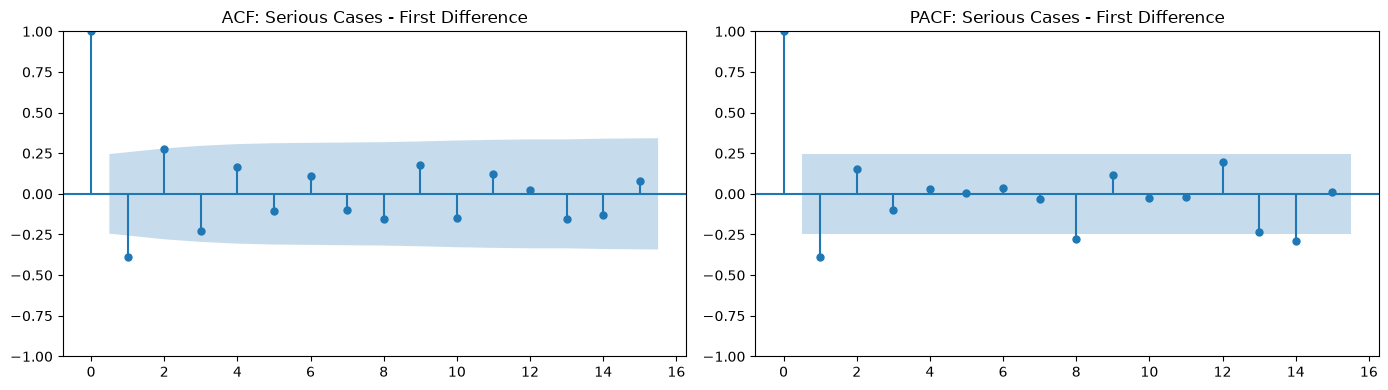

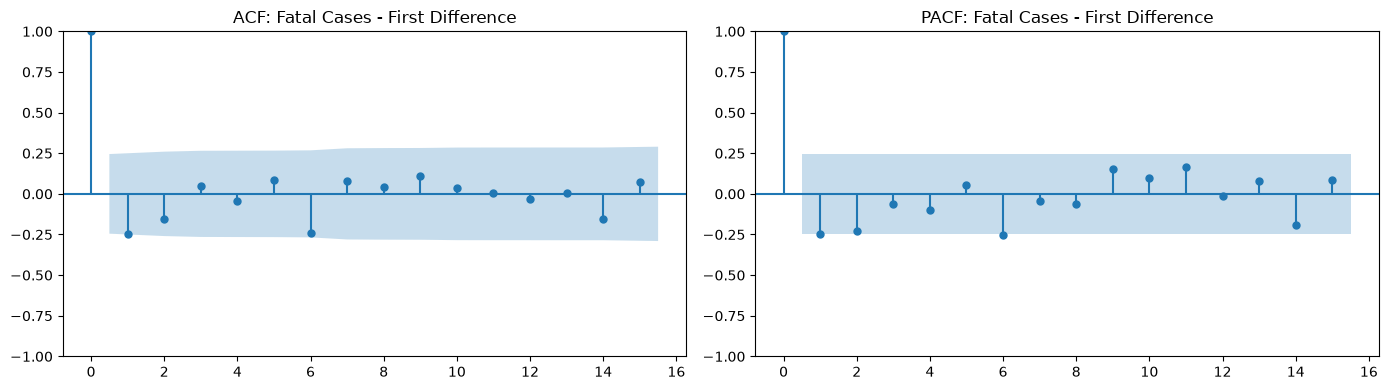

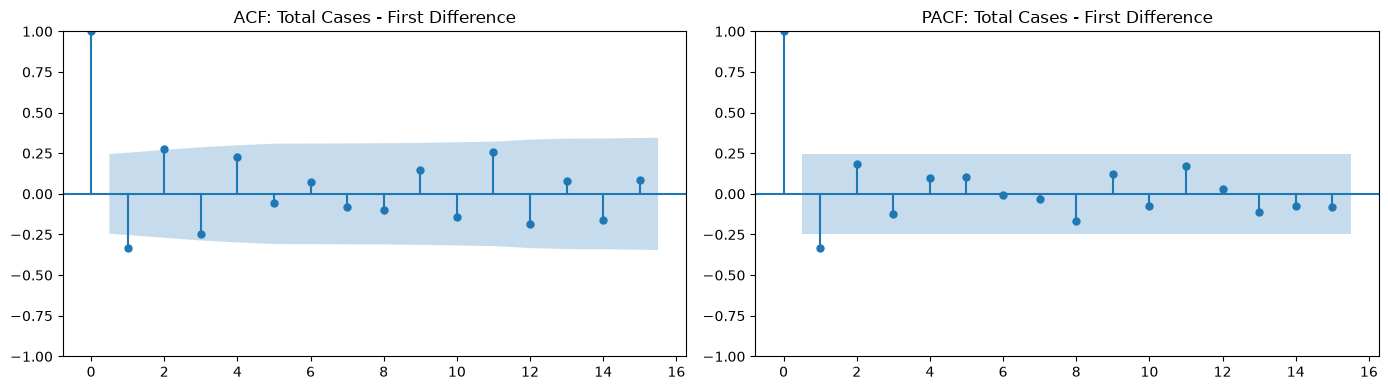

In [174]:
# Create stationary versions of each series
extended_df["Minor_Diff2"] = extended_df["Minor Cases"].diff().diff()
extended_df["Serious_Diff1"] = extended_df["Serious Cases"].diff()
extended_df["Fatal_Diff1"] = extended_df["Fatal Cases"].diff()
extended_df["Total_Diff1"] = extended_df["Total Cases"].diff()

series_to_plot = {
    "Minor Cases - Second Difference": extended_df["Minor_Diff2"],
    "Serious Cases - First Difference": extended_df["Serious_Diff1"],
    "Fatal Cases - First Difference": extended_df["Fatal_Diff1"],
    "Total Cases - First Difference": extended_df["Total_Diff1"]
}

for name, series in series_to_plot.items():
    
    clean_series = series.dropna()

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    plot_acf(
        clean_series,
        lags=15,
        ax=axes[0]
    )
    axes[0].set_title(f"ACF: {name}")

    plot_pacf(
        clean_series,
        lags=15,
        ax=axes[1],
        method="ywm"
    )
    axes[1].set_title(f"PACF: {name}")

    plt.tight_layout()
    plt.show()

#### comparing candidate ARIMA models

In [177]:
# Candidate models for each outcome
candidates = {
    "Minor Cases": [
        (0,1,1), (1,1,0), (1,1,1),
        (0,2,1), (1,2,0), (1,2,1)
    ],
    
    "Serious Cases": [
        (0,1,1), (1,1,0), (1,1,1)
    ],
    
    "Fatal Cases": [
        (0,1,0), (0,1,1), (1,1,0), (1,1,1)
    ],
    
    "Total Cases": [
        (0,1,1), (1,1,0), (1,1,1)
    ]
}

results = []

for outcome, orders in candidates.items():

    series = extended_df[outcome].dropna()

    for order in orders:

        try:
            model = ARIMA(series, order=order)
            fit = model.fit()

            results.append({
                "Outcome": outcome,
                "ARIMA": str(order),
                "AIC": fit.aic,
                "BIC": fit.bic
            })

        except Exception as e:
            print(f"Could not fit {outcome} ARIMA{order}: {e}")

arima_comparison = pd.DataFrame(results)

arima_comparison = arima_comparison.sort_values(
    ["Outcome", "AIC"]
)

arima_comparison.round(2)

,Outcome,ARIMA,AIC,BIC
10,Fatal Cases,"(0, 1, 1)",1064.65,1068.97
12,Fatal Cases,"(1, 1, 1)",1065.42,1071.90
11,Fatal Cases,"(1, 1, 0)",1067.17,1071.48
9,Fatal Cases,"(0, 1, 0)",1069.30,1071.46
5,Minor Cases,"(1, 2, 1)",1131.41,1137.84
3,Minor Cases,"(0, 2, 1)",1137.66,1141.94
2,Minor Cases,"(1, 1, 1)",1143.21,1149.69
1,Minor Cases,"(1, 1, 0)",1143.52,1147.84
0,Minor Cases,"(0, 1, 1)",1145.42,1149.73
4,Minor Cases,"(1, 2, 0)",1148.08,1152.36


### Rolling One-Year-Ahead ARIMA Forecast Evaluation (2014–2024)

The previous analysis examined different ARIMA specifications using the complete 1960–2024 dataset. However, model selection measures such as AIC and BIC assess model fit rather than forecasting accuracy on unseen data.

To evaluate forecasting performance, an expanding-window one-year-ahead approach was applied. For each year between 2014 and 2024, the models were fitted using only the observations available before the forecast year.

For example:

Data from 1960–2013 were used to forecast 2014.

Data from 1960–2014 were used to forecast 2015.

Data from 1960–2015 were used to forecast 2016.

This process continued until 2024, with the training period expanding by one year for each forecast. This approach maintains the chronological order of the data and ensures that future observations are not included when generating forecasts for earlier years.

The ARIMA models originally used by Sanusi et al. (2016) were evaluated alongside alternative specifications identified from the extended 1960–2024 dataset. However, because these alternative specifications were selected using the complete dataset, their evaluation is treated as a retrospective sensitivity analysis rather than a fully independent out-of-sample model selection exercise.

In [180]:
# define candidate models

# ARIMA specifications to evaluate using rolling one-year-ahead forecasts

arima_candidates = {
    "Minor Cases": {
        "Sanusi_ARIMA(1,1,1)": (1, 1, 1),
        "Updated_ARIMA(1,2,1)": (1, 2, 1),
        "Alternative_ARIMA(0,2,1)": (0, 2, 1)
    },

    "Serious Cases": {
        "Sanusi_ARIMA(1,1,0)": (1, 1, 0),
        "Updated_ARIMA(1,1,1)": (1, 1, 1)
    },

    "Fatal Cases": {
        "Sanusi_ARIMA(0,1,1)": (0, 1, 1)
    },

    "Total Cases": {
        "Sanusi_ARIMA(1,1,1)": (1, 1, 1),
        "Alternative_ARIMA(1,1,0)": (1, 1, 0)
    }
}

arima_candidates

{'Minor Cases': {'Sanusi_ARIMA(1,1,1)': (1, 1, 1),
  'Updated_ARIMA(1,2,1)': (1, 2, 1),
  'Alternative_ARIMA(0,2,1)': (0, 2, 1)},
 'Serious Cases': {'Sanusi_ARIMA(1,1,0)': (1, 1, 0),
  'Updated_ARIMA(1,1,1)': (1, 1, 1)},
 'Fatal Cases': {'Sanusi_ARIMA(0,1,1)': (0, 1, 1)},
 'Total Cases': {'Sanusi_ARIMA(1,1,1)': (1, 1, 1),
  'Alternative_ARIMA(1,1,0)': (1, 1, 0)}}

In [184]:
# build the rolling forecasting fn

# ARIMA specifications to evaluate using rolling one-year-ahead forecasts

def rolling_arima_forecast(data, column, order, start_year=2014, end_year=2024):
    
    results = []

    for forecast_year in range(start_year, end_year + 1):

        # Training data contains ONLY years before the year being forecast
        train = data.loc[
            data["Year"] < forecast_year,
            column
        ].dropna()

        # Fit ARIMA model
        model = ARIMA(train, order=order)
        fitted_model = model.fit()

        # Forecast one year ahead
        forecast = fitted_model.forecast(steps=1).iloc[0]

        # Retrieve actual observed value
        actual = data.loc[
            data["Year"] == forecast_year,
            column
        ].iloc[0]

        results.append({
            "Year": forecast_year,
            "Actual": actual,
            "Forecast": forecast,
            "Error": actual - forecast,
            "Absolute_Error": abs(actual - forecast),
            "APE": abs((actual - forecast) / actual) * 100
        })

    return pd.DataFrame(results)

In [186]:
# run every candidate model

rolling_results = []

for outcome, models in arima_candidates.items():

    for model_name, order in models.items():

        forecasts = rolling_arima_forecast(
            data=extended_df,
            column=outcome,
            order=order,
            start_year=2014,
            end_year=2024
        )

        forecasts["Outcome"] = outcome
        forecasts["Model"] = model_name
        forecasts["ARIMA_Order"] = str(order)

        rolling_results.append(forecasts)

rolling_results = pd.concat(
    rolling_results,
    ignore_index=True
)

rolling_results.head(20).round(2)

,Year,Actual,Forecast,Error,Absolute_Error,APE,Outcome,Model,ARIMA_Order
0,2014,907,1804.77,-897.77,897.77,98.98,Minor Cases,"Sanusi_ARIMA(1,1,1)","(1, 1, 1)"
1,2015,841,1056.25,-215.25,215.25,25.59,Minor Cases,"Sanusi_ARIMA(1,1,1)","(1, 1, 1)"
2,2016,1423,789.13,633.87,633.87,44.54,Minor Cases,"Sanusi_ARIMA(1,1,1)","(1, 1, 1)"
3,2017,1340,1302.54,37.46,37.46,2.80,Minor Cases,"Sanusi_ARIMA(1,1,1)","(1, 1, 1)"
4,2018,1153,1415.90,-262.90,262.90,22.80,Minor Cases,"Sanusi_ARIMA(1,1,1)","(1, 1, 1)"
5,2019,1265,1164.44,100.56,100.56,7.95,Minor Cases,"Sanusi_ARIMA(1,1,1)","(1, 1, 1)"
6,2020,1347,1231.96,115.04,115.04,8.54,Minor Cases,"Sanusi_ARIMA(1,1,1)","(1, 1, 1)"
7,2021,1485,1341.86,143.14,143.14,9.64,Minor Cases,"Sanusi_ARIMA(1,1,1)","(1, 1, 1)"
8,2022,1394,1453.12,-59.12,59.12,4.24,Minor Cases,"Sanusi_ARIMA(1,1,1)","(1, 1, 1)"
9,2023,1041,1431.30,-390.30,390.30,37.49,Minor Cases,"Sanusi_ARIMA(1,1,1)","(1, 1, 1)"


In [188]:
# calc MAE, RMSE, MAPE

rolling_summary = (
    rolling_results
    .groupby(["Outcome", "Model", "ARIMA_Order"])
    .apply(
        lambda x: pd.Series({
            "MAE": mean_absolute_error(
                x["Actual"],
                x["Forecast"]
            ),
            "RMSE": np.sqrt(
                mean_squared_error(
                    x["Actual"],
                    x["Forecast"]
                )
            ),
            "MAPE (%)": x["APE"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

rolling_summary.round(2)

,Outcome,Model,ARIMA_Order,MAE,RMSE,MAPE (%)
0,Fatal Cases,"Sanusi_ARIMA(0,1,1)","(0, 1, 1)",237.90,278.98,8.54
1,Minor Cases,"Alternative_ARIMA(0,2,1)","(0, 2, 1)",244.66,340.70,21.00
2,Minor Cases,"Sanusi_ARIMA(1,1,1)","(1, 1, 1)",278.16,377.32,25.92
3,Minor Cases,"Updated_ARIMA(1,2,1)","(1, 2, 1)",300.19,398.38,25.51
4,Serious Cases,"Sanusi_ARIMA(1,1,0)","(1, 1, 0)",1045.35,1182.92,15.55
5,Serious Cases,"Updated_ARIMA(1,1,1)","(1, 1, 1)",983.28,1141.10,14.64
6,Total Cases,"Alternative_ARIMA(1,1,0)","(1, 1, 0)",1354.58,1641.90,12.64
7,Total Cases,"Sanusi_ARIMA(1,1,1)","(1, 1, 1)",1326.17,1621.46,12.41


### Interpretation of Rolling One-Year-Ahead ARIMA Forecast Results

The rolling one-year-ahead evaluation assessed the forecasting accuracy of the ARIMA models between 2014 and 2024. For each year, the models were refitted using only the observations available up to the previous year. This allowed forecasting performance to be assessed using data that were not included in the model estimation for each prediction.

The results showed differences in forecasting accuracy across the four road traffic crash categories.

**Fatal Cases**: The ARIMA(0,1,1) model used by Sanusi et al. (2016) recorded an MAE of 237.90, RMSE of 278.98 and MAPE of 8.54%. This was the lowest percentage forecasting error across the four crash categories.

**Minor Cases**: The alternative ARIMA(0,2,1) model achieved the lowest errors, with an MAE of 244.66, RMSE of 340.70 and MAPE of 21.00%. This performed better than both the original ARIMA(1,1,1) model and the ARIMA(1,2,1) specification, which had the lowest AIC using the extended dataset. This suggests that a model with a better fit to the historical data does not necessarily produce more accurate forecasts.

**Serious Cases**: The alternative ARIMA(1,1,1) model recorded an MAE of 983.28, RMSE of 1,141.10 and MAPE of 14.64%. These were lower than the errors recorded by Sanusi et al.'s ARIMA(1,1,0) model, which achieved an MAE of 1,045.35, RMSE of 1,182.92 and MAPE of 15.55%. This indicates a modest improvement in forecasting accuracy when using the alternative specification.

**Total Cases**: The original ARIMA(1,1,1) model remained slightly more accurate than the alternative ARIMA(1,1,0) model. It recorded an MAE of 1,326.17, RMSE of 1,621.46 and MAPE of 12.41%, compared with 1,354.58, 1,641.90 and 12.64%, respectively, for the alternative model.

Overall, the findings indicate that extending the historical dataset to 2024 did not produce a single alternative ARIMA specification that performed better across all crash categories. While the alternative models improved forecasting accuracy for Minor and Serious Cases, the original specifications remained competitive for Fatal and Total Cases.

However, it is important to distinguish these results from the original forecasts published by Sanusi et al. (2016). In this evaluation, the models were refitted each year as new observations became available, rather than using the original fitted models to forecast the entire period through 2024. Therefore, the findings assess whether the original ARIMA model specifications remain suitable for more recent one-year-ahead forecasting, rather than whether the original published forecasts remained accurate.

Additionally, because the alternative ARIMA specifications were identified using the complete 1960–2024 dataset, their comparative results should be interpreted as a retrospective sensitivity analysis rather than a fully independent model-selection exercise.

### Naïve Forecast Benchmark

A naïve one-year-ahead forecasting method was used as a benchmark to assess whether the ARIMA models provided better forecasting accuracy than a simple prediction approach.

The naïve method uses the actual recorded value from the previous year to predict the following year. For example, the 2013 value was used to forecast 2014, while the 2014 value was used to forecast 2015. This process continued until 2024.

The benchmark was evaluated over the same 2014–2024 period using MAE, RMSE and MAPE. The results provide a baseline for comparing the forecasting accuracy of the ARIMA models and determining whether they offer an improvement over simply using the previous year's recorded values.

In [192]:
naive_results = []

for outcome in ["Minor Cases", "Serious Cases", "Fatal Cases", "Total Cases"]:
    
    temp = extended_df[["Year", outcome]].copy()
    
    # Previous year's actual value becomes this year's forecast
    temp["Forecast"] = temp[outcome].shift(1)
    
    # Only evaluate 2014–2024
    temp = temp[
        (temp["Year"] >= 2014) &
        (temp["Year"] <= 2024)
    ].copy()
    
    temp["Actual"] = temp[outcome]
    temp["Error"] = temp["Actual"] - temp["Forecast"]
    temp["Absolute_Error"] = abs(temp["Error"])
    temp["APE"] = (
        temp["Absolute_Error"] / temp["Actual"]
    ) * 100
    
    naive_results.append({
        "Outcome": outcome,
        "Model": "Naive Previous-Year",
        "MAE": temp["Absolute_Error"].mean(),
        "RMSE": np.sqrt((temp["Error"] ** 2).mean()),
        "MAPE (%)": temp["APE"].mean()
    })

naive_summary = pd.DataFrame(naive_results)

naive_summary.round(2)

,Outcome,Model,MAE,RMSE,MAPE (%)
0,Minor Cases,Naive Previous-Year,238.27,330.69,21.64
1,Serious Cases,Naive Previous-Year,859.27,1074.92,12.72
2,Fatal Cases,Naive Previous-Year,200.55,256.22,7.13
3,Total Cases,Naive Previous-Year,1141.73,1518.79,10.61


In [194]:
comparison_summary = pd.concat([
    rolling_summary[
        ["Outcome", "Model", "MAE", "RMSE", "MAPE (%)"]
    ],
    naive_summary
], ignore_index=True)

comparison_summary = comparison_summary.sort_values(
    ["Outcome", "RMSE"]
)

comparison_summary.round(2)

,Outcome,Model,MAE,RMSE,MAPE (%)
10,Fatal Cases,Naive Previous-Year,200.55,256.22,7.13
0,Fatal Cases,"Sanusi_ARIMA(0,1,1)",237.90,278.98,8.54
8,Minor Cases,Naive Previous-Year,238.27,330.69,21.64
1,Minor Cases,"Alternative_ARIMA(0,2,1)",244.66,340.70,21.00
2,Minor Cases,"Sanusi_ARIMA(1,1,1)",278.16,377.32,25.92
3,Minor Cases,"Updated_ARIMA(1,2,1)",300.19,398.38,25.51
9,Serious Cases,Naive Previous-Year,859.27,1074.92,12.72
5,Serious Cases,"Updated_ARIMA(1,1,1)",983.28,1141.10,14.64
4,Serious Cases,"Sanusi_ARIMA(1,1,0)",1045.35,1182.92,15.55
11,Total Cases,Naive Previous-Year,1141.73,1518.79,10.61


### Comparison with the Naïve Previous-Year Benchmark

The rolling ARIMA forecasts were compared with a naïve one-year-ahead benchmark, which uses the actual recorded value from the previous year to predict the following year. Both approaches were evaluated over the 2014–2024 period using MAE, RMSE and MAPE.

For **Fatal Cases**, the naïve benchmark recorded an MAE of 200.55, RMSE of 256.22 and MAPE of 7.13%. These errors were lower than those obtained from Sanusi et al.'s ARIMA(0,1,1) model, which recorded an MAE of 237.90, RMSE of 278.98 and MAPE of 8.54%.

A similar pattern was observed for **Serious Cases**. The naïve benchmark achieved an MAE of 859.27, RMSE of 1,074.92 and MAPE of 12.72%, compared with an MAE of 983.28, RMSE of 1,141.10 and MAPE of 14.64% for the alternative ARIMA(1,1,1) model. The original ARIMA(1,1,0) specification produced even higher forecasting errors.

For **Total Cases**, the naïve benchmark also performed better, recording an MAE of 1,141.73, RMSE of 1,518.79 and MAPE of 10.61%. In comparison, Sanusi et al.'s ARIMA(1,1,1) model recorded an MAE of 1,326.17, RMSE of 1,621.46 and MAPE of 12.41%.

However, the results for **Minor Cases** were slightly different. The naïve benchmark achieved the lowest MAE of 238.27 and RMSE of 330.69, while the alternative ARIMA(0,2,1) model recorded a slightly lower MAPE of 21.00%, compared with 21.64% for the naïve benchmark. This indicates that neither approach performed better across all three evaluation measures for Minor Cases.

Overall, the findings show that the ARIMA models did not consistently outperform the naïve benchmark during the 2014–2024 evaluation period. Although the ARIMA models produced reasonable forecasts for some crash categories, their additional complexity did not consistently result in better forecasting accuracy than simply using the previous year's recorded values.

These results highlight the importance of comparing forecasting models against a simple baseline rather than relying only on model selection measures such as AIC and BIC. The naïve benchmark is therefore retained for the subsequent comparison with Linear Regression, Random Forest and Gradient Boosting models.